# Punto 2 — Pérdida dado Incumplimiento (LGD)
## Regla de Comparación Justa y Evaluación de 30 Semillas Independientes

**Asignatura:** Redes Neuronales y Algoritmos Bioinspirados  
**Institución:** Universidad Nacional de Colombia — Facultad de Minas  
**Semestre:** 2026-02  

---
### Propósito del Experimento

En este notebook se formaliza el cumplimiento estricto de la **Regla de comparación justa** establecida en la guía oficial del trabajo para la tarea de regresión (estimación de la severidad de pérdida o LGD):

1. **Mismos datos y particiones:** Tanto el modelo de baja complejidad (Regresión Lineal OLS) como el Perceptrón Multicapa (MLP) se entrenan y evalúan exactamente sobre las mismas particiones (`data/processed/lgd_limpio.parquet`: 60% entrenamiento, 20% validación y 20% prueba) y con el mismo preprocesador ajustado exclusivamente en entrenamiento.
2. **Presupuesto de búsqueda explícito:** Se evalúan arquitecturas candidatas sobre el conjunto de validación (usando una semilla fija para búsqueda) y se reporta el tiempo de cómputo invertido.
3. **Varias corridas independientes (30 semillas):** La arquitectura ganadora se entrena de forma independiente a lo largo de **30 semillas aleatorias distintas**, reportando la media, desviación estándar, mejor (mínimo) y peor (máximo) valor de cada métrica de evaluación.
4. **Complejidad:** Se reporta y compara el número de parámetros entrenables de cada familia de modelos.

In [1]:
from pathlib import Path
import sys
import time
import json

# Configurar la ruta raíz del repositorio
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/red_neuronal.py').exists()), None)
if RAIZ is None:
    raise FileNotFoundError('Ejecute el notebook dentro del repositorio del proyecto')
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

from src.red_neuronal import RedNeuronal
from src.preprocesamiento import construir_preprocesador
from src.configuracion import cargar_config
from src.metricas import mae, rmse, resumen_regresion, comparar_distribuciones

# Configuración estética
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

RUTA_DATOS = RAIZ / 'data/processed/lgd_limpio.parquet'
CARPETA_REPORTS = RAIZ / 'reports/lgd'
CARPETA_REPORTS.mkdir(parents=True, exist_ok=True)

print(f'Directorio raíz: {RAIZ}')
print(f'Ruta datos LGD: {RUTA_DATOS}')

Directorio raíz: c:\Users\ADMON\Documents\Universidad\Redes Neuronales\Trabajos\trabajo_2\T02_REDES_NEURONALES_
Ruta datos LGD: c:\Users\ADMON\Documents\Universidad\Redes Neuronales\Trabajos\trabajo_2\T02_REDES_NEURONALES_\data\processed\lgd_limpio.parquet


--- 
### 1. Carga y Verificación de los Datos Procesados

Cargamos `lgd_limpio.parquet`, el cual contiene la muestra de créditos de Lending Club que presentaron incumplimiento (`Charged Off` y `Default`), totalizando 46.467 registros con la partición fija 60/20/20 y la variable objetivo LGD acotada en $[0, 1]$.

In [2]:
df_lgd = pd.read_parquet(RUTA_DATOS)
print(f'Registros totales cargados: {len(df_lgd):,}')
display(df_lgd.groupby('particion')['lgd'].agg(['count', 'mean', 'std', 'min', 'max']))

cfg = cargar_config(RAIZ / 'config.ini', 'lgd')
d_cfg = cfg['datos']
columnas_modelo = list(dict.fromkeys(d_cfg['numericas'] + d_cfg['categoricas']))

partes = {p: df_lgd.loc[df_lgd['particion'] == p] for p in ('train', 'valid', 'test')}
y = {p: partes[p]['lgd'].to_numpy(dtype=float) for p in ('train', 'valid', 'test')}

# Ajustar preprocesador exclusivamente con el conjunto de entrenamiento
preprocesador = construir_preprocesador(d_cfg['numericas'], d_cfg['categoricas'], d_cfg['logaritmicas'])
X = {'train': preprocesador.fit_transform(partes['train'][columnas_modelo])}
X['valid'] = preprocesador.transform(partes['valid'][columnas_modelo])
X['test'] = preprocesador.transform(partes['test'][columnas_modelo])

print(f'Dimensiones de la matriz X (train): {X["train"].shape}')
print(f'Variables de entrada transformadas: {X["train"].shape[1]}')

Registros totales cargados: 46,467


,count,mean,std,min,max
particion,,,,,
test,9294,0.749883,0.201782,0.010475,1.0
train,27879,0.748207,0.200043,0.000000,1.0
valid,9294,0.751166,0.198443,0.012690,1.0


Dimensiones de la matriz X (train): (27879, 38)
Variables de entrada transformadas: 38


--- 
### 2. Modelo de Referencia: Regresión Lineal Clásica (OLS)

Ajustamos una regresión lineal ordinaria por mínimos cuadrados (OLS) como modelo de referencia de baja complejidad. Al ser un estimador analítico determinista, no presenta variabilidad por inicialización estocástica.

In [3]:
inicio_ols = time.perf_counter()
modelo_ols = LinearRegression().fit(X['train'], y['train'])
tiempo_ols = time.perf_counter() - inicio_ols

pred_ols_test = modelo_ols.predict(X['test'])
metricas_ols = resumen_regresion(y['test'], pred_ols_test)
parametros_ols = X['train'].shape[1] + 1  # coeficientes + intercepto
metricas_ols.update(parametros=parametros_ols, segundos=tiempo_ols)

fuera_rango = int(((pred_ols_test < 0) | (pred_ols_test > 1)).sum())
print('=== MODELO DE REFERENCIA: REGRESIÓN LINEAL (OLS) ===')
print(f'Tiempo de ajuste: {tiempo_ols:.4f} s')
print(f'Parámetros entrenables: {parametros_ols}')
print(f'MAE en Test:  {metricas_ols["mae"]:.6f} ({100*metricas_ols["mae"]:.2f} puntos porcentuales)')
print(f'RMSE en Test: {metricas_ols["rmse"]:.6f} ({100*metricas_ols["rmse"]:.2f} puntos porcentuales)')
print(f'Predicciones fuera de [0, 1]: {fuera_rango}')

pd.DataFrame([metricas_ols]).to_csv(CARPETA_REPORTS / 'referencia_ols.csv', index=False)

=== MODELO DE REFERENCIA: REGRESIÓN LINEAL (OLS) ===
Tiempo de ajuste: 0.2568 s
Parámetros entrenables: 39
MAE en Test:  0.142536 (14.25 puntos porcentuales)
RMSE en Test: 0.186237 (18.62 puntos porcentuales)
Predicciones fuera de [0, 1]: 2


--- 
### 3. Búsqueda y Optimización de la Red Neuronal (Presupuesto Explícito)

Definimos un presupuesto de búsqueda reproducible con diferentes configuraciones candidatas. La selección se realiza **únicamente a partir del menor MAE sobre el conjunto de validación** (utilizando la semilla base 42). El conjunto de prueba se mantiene intacto y sin consultar durante la selección.

In [4]:
candidatos = [
    dict(capas_ocultas=(16,), activacion='tanh', l2=0.0001, dropout=0.0, tasa=0.001),
    dict(capas_ocultas=(32, 16), activacion='relu', l2=0.0001, dropout=0.1, tasa=0.001),
    dict(capas_ocultas=(32, 16), activacion='tanh', l2=0.001, dropout=0.1, tasa=0.003),
]

resultados_busqueda = []
inicio_busqueda = time.perf_counter()

for i, c in enumerate(candidatos):
    t0 = time.perf_counter()
    red_temp = RedNeuronal(
        X['train'].shape[1],
        capas_ocultas=c['capas_ocultas'],
        activacion=c['activacion'],
        salida='sigmoide',
        perdida='ecm',
        l2=c['l2'],
        dropout=c['dropout'],
        semilla=42
    )
    red_temp.entrenar(
        X['train'], y['train'],
        X['valid'], y['valid'],
        optimizador='adam',
        tasa=c['tasa'],
        epocas=200,
        tam_lote=256,
        paciencia=10,
        verbose=False
    )
    duracion = time.perf_counter() - t0
    mae_val = mae(y['valid'], red_temp.predecir(X['valid']))
    rmse_val = rmse(y['valid'], red_temp.predecir(X['valid']))
    resultados_busqueda.append({
        'candidato': i + 1,
        'arquitectura': str(c['capas_ocultas']),
        'activacion': c['activacion'],
        'l2': c['l2'],
        'dropout': c['dropout'],
        'tasa': c['tasa'],
        'mae_valid': mae_val,
        'rmse_valid': rmse_val,
        'parametros': red_temp.contar_parametros(),
        'segundos': duracion,
        'mejor_epoca': red_temp.mejor_epoca
    })

tiempo_total_busqueda = time.perf_counter() - inicio_busqueda
df_busqueda = pd.DataFrame(resultados_busqueda)
mejor_idx = df_busqueda['mae_valid'].idxmin()
config_ganadora = candidatos[mejor_idx]

print(f'Tiempo total de búsqueda: {tiempo_total_busqueda:.2f} s')
print(f'Configuración seleccionada (Candidato {mejor_idx + 1}): {config_ganadora}')
display(df_busqueda)
df_busqueda.to_csv(CARPETA_REPORTS / 'busqueda_hiperparametros_lgd.csv', index=False)

Tiempo total de búsqueda: 34.99 s
Configuración seleccionada (Candidato 2): {'capas_ocultas': (32, 16), 'activacion': 'relu', 'l2': 0.0001, 'dropout': 0.1, 'tasa': 0.001}


,candidato,arquitectura,activacion,l2,dropout,tasa,mae_valid,rmse_valid,parametros,segundos,mejor_epoca
0,1,"(16,)",tanh,0.0001,0.0,0.001,0.139782,0.182027,641,10.256550,66
1,2,"(32, 16)",relu,0.0001,0.1,0.001,0.139579,0.181704,1793,13.486793,56
2,3,"(32, 16)",tanh,0.0010,0.1,0.003,0.140192,0.182907,1793,11.164749,22


--- 
### 4. Evaluación de 30 Semillas Independientes (Regla de Comparación Justa)

Entrenamos la configuración ganadora con **30 semillas aleatorias independientes** (semillas 42 a 71). Esto permite cuantificar la estabilidad del algoritmo frente a la inicialización de pesos y el barajado estocástico de los lotes.

In [5]:
semillas = list(range(42, 72))  # 30 semillas distintas
corridas = []
predicciones_semillas = {'y_test': y['test'], 'pred_ols': pred_ols_test}

print(f'Iniciando entrenamiento de 30 semillas independientes...')
inicio_30_semillas = time.perf_counter()

for s in semillas:
    t_start = time.perf_counter()
    red_s = RedNeuronal(
        X['train'].shape[1],
        capas_ocultas=config_ganadora['capas_ocultas'],
        activacion=config_ganadora['activacion'],
        salida='sigmoide',
        perdida='ecm',
        l2=config_ganadora['l2'],
        dropout=config_ganadora['dropout'],
        semilla=s
    )
    red_s.entrenar(
        X['train'], y['train'],
        X['valid'], y['valid'],
        optimizador='adam',
        tasa=config_ganadora['tasa'],
        epocas=200,
        tam_lote=256,
        paciencia=10,
        verbose=False
    )
    t_end = time.perf_counter() - t_start
    
    # Predicciones y métricas en test
    pred_s = red_s.predecir(X['test'])
    predicciones_semillas[f'pred_semilla_{s}'] = pred_s
    
    m_train = resumen_regresion(y['train'], red_s.predecir(X['train']))
    m_val = resumen_regresion(y['valid'], red_s.predecir(X['valid']))
    m_test = resumen_regresion(y['test'], pred_s)
    
    corridas.append({
        'semilla': s,
        'mejor_epoca': red_s.mejor_epoca,
        'segundos': t_end,
        'parametros': red_s.contar_parametros(),
        'mae_train': m_train['mae'],
        'rmse_train': m_train['rmse'],
        'mae_valid': m_val['mae'],
        'rmse_valid': m_val['rmse'],
        'mae_test': m_test['mae'],
        'rmse_test': m_test['rmse'],
        'ks_test': m_test['ks_distribuciones']
    })

tiempo_total_semillas = time.perf_counter() - inicio_30_semillas
df_semillas = pd.DataFrame(corridas)
print(f'Entrenamiento completado en {tiempo_total_semillas:.2f} s ({tiempo_total_semillas/60:.2f} min)')

# Guardar archivos de resultados
df_semillas.to_csv(RAIZ / 'reports/semillas_lgd_mlp.csv', index=False)
df_semillas.to_csv(CARPETA_REPORTS / 'corridas.csv', index=False)
np.savez_compressed(CARPETA_REPORTS / 'predicciones_comparadas.npz', **predicciones_semillas)
display(df_semillas.head(10))

Iniciando entrenamiento de 30 semillas independientes...
Entrenamiento completado en 426.88 s (7.11 min)


,semilla,mejor_epoca,segundos,parametros,mae_train,rmse_train,mae_valid,rmse_valid,mae_test,rmse_test,ks_test
0,42,56,17.009000,1793,0.138429,0.181061,0.139579,0.181704,0.141461,0.185119,0.277383
1,43,53,12.235077,1793,0.138704,0.181349,0.139685,0.181596,0.141507,0.184966,0.283516
2,44,34,9.021504,1793,0.138627,0.181623,0.139534,0.181735,0.141429,0.185200,0.274478
3,45,33,9.076765,1793,0.138495,0.181768,0.139094,0.181593,0.140969,0.185256,0.263611
4,46,46,10.765943,1793,0.138815,0.181164,0.140065,0.181709,0.141920,0.185124,0.285238
5,47,62,15.588290,1793,0.138738,0.180878,0.140028,0.181656,0.141679,0.184787,0.282978
6,48,43,18.133083,1793,0.138157,0.181226,0.139162,0.181577,0.141149,0.185139,0.271896
7,49,49,35.448934,1793,0.138497,0.181548,0.139435,0.181775,0.141195,0.185129,0.274155
8,50,47,20.052473,1793,0.138092,0.181392,0.138997,0.181622,0.140933,0.185073,0.271573
9,51,61,17.755997,1793,0.138469,0.181004,0.139867,0.181775,0.141585,0.185083,0.278459


--- 
### 5. Tabla Resumen y Comparación Justa Frente a OLS

Calculamos los estadísticos agregados exigidos por la rúbrica (**Media, Desviación Estándar, Mejor y Peor valor**) a lo largo de las 30 corridas independientes, contrastándolos con la referencia OLS.

In [6]:
resumen_estadistico = df_semillas[['mae_test', 'rmse_test', 'ks_test']].agg(['mean', 'std', 'min', 'max']).rename(
    index={'mean': 'Media', 'std': 'Desv. Estándar', 'min': 'Mejor (Mínimo)', 'max': 'Peor (Máximo)'}
)

display(resumen_estadistico)
resumen_estadistico.to_csv(CARPETA_REPORTS / 'resumen_semillas.csv', index_label='estadistico')

# Comparación formal frente a OLS
mae_ols = metricas_ols['mae']
rmse_ols = metricas_ols['rmse']
mae_mlp_media = df_semillas['mae_test'].mean()
rmse_mlp_media = df_semillas['rmse_test'].mean()

mejora_mae = (mae_ols - mae_mlp_media) / mae_ols * 100
mejora_rmse = (rmse_ols - rmse_mlp_media) / rmse_ols * 100
victorias_mae = int((df_semillas['mae_test'] < mae_ols).sum())
victorias_rmse = int((df_semillas['rmse_test'] < rmse_ols).sum())

tabla_comparativa = pd.DataFrame({
    'Métrica': ['MAE (Test)', 'RMSE (Test)', 'Parámetros', 'Tiempo Ajuste (s)'],
    'Referencia OLS': [f'{mae_ols:.6f}', f'{rmse_ols:.6f}', f'{parametros_ols}', f'{tiempo_ols:.4f}'],
    'Red MLP (Media ± Desv)': [
        f'{mae_mlp_media:.6f} ± {df_semillas["mae_test"].std():.6f}',
        f'{rmse_mlp_media:.6f} ± {df_semillas["rmse_test"].std():.6f}',
        f'{int(df_semillas["parametros"].iloc[0])}',
        f'{df_semillas["segundos"].mean():.2f} ± {df_semillas["segundos"].std():.2f}'
    ],
    'Mejora Relativa (%)': [f'{mejora_mae:+.2f}%', f'{mejora_rmse:+.2f}%', '-', '-'],
    'Semillas que Superan OLS': [f'{victorias_mae}/30', f'{victorias_rmse}/30', '-', '-']
})

print('=== COMPARACIÓN FORMAL: OLS vs. RED NEURONAL (30 SEMILLAS) ===')
display(tabla_comparativa)
tabla_comparativa.to_csv(CARPETA_REPORTS / 'tabla_comparativa_ols_vs_mlp.csv', index=False)

,mae_test,rmse_test,ks_test
Media,0.141219,0.185083,0.273481
Desv. Estándar,0.000345,0.000142,0.006397
Mejor (Mínimo),0.140489,0.184787,0.260275
Peor (Máximo),0.141920,0.185320,0.285238


=== COMPARACIÓN FORMAL: OLS vs. RED NEURONAL (30 SEMILLAS) ===


,Métrica,Referencia OLS,Red MLP (Media ± Desv),Mejora Relativa (%),Semillas que Superan OLS
0,MAE (Test),0.142536,0.141219 ± 0.000345,+0.92%,30/30
1,RMSE (Test),0.186237,0.185083 ± 0.000142,+0.62%,30/30
2,Parámetros,39,1793,-,-
3,Tiempo Ajuste (s),0.2568,14.14 ± 5.70,-,-


--- 
### 6. Visualizaciones del Rendimiento y Comparación de Distribuciones

Generamos las figuras de evaluación exigidas:
1. **Dispersión de métricas:** Distribución del error a través de las 30 semillas frente a la referencia fija OLS.
2. **Comparación de distribuciones (Histograma y Curvas CDF):** Distribución de la LGD observada vs. LGD predicha por OLS y por la Red Neuronal.

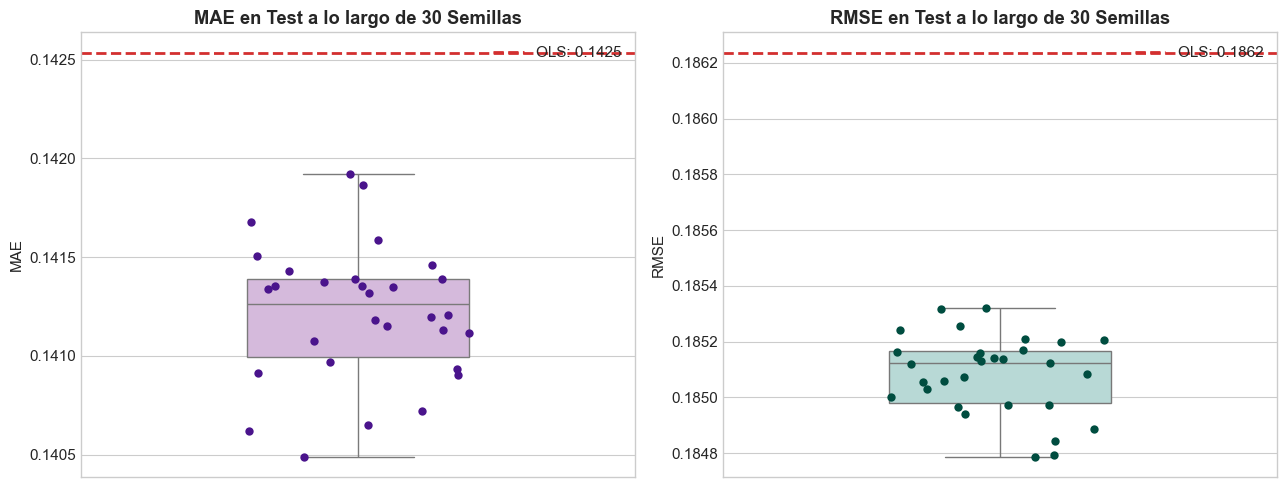

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Boxplot / Stripplot MAE
sns.boxplot(y=df_semillas['mae_test'], ax=axes[0], color='#d8b4e2', width=0.4)
sns.stripplot(y=df_semillas['mae_test'], ax=axes[0], color='#4a148c', size=6, jitter=0.2)
axes[0].axhline(mae_ols, color='#d32f2f', linestyle='--', linewidth=2, label=f'OLS: {mae_ols:.4f}')
axes[0].set_title('MAE en Test a lo largo de 30 Semillas', fontweight='bold')
axes[0].set_ylabel('MAE')
axes[0].legend(loc='upper right')

# Boxplot / Stripplot RMSE
sns.boxplot(y=df_semillas['rmse_test'], ax=axes[1], color='#b2dfdb', width=0.4)
sns.stripplot(y=df_semillas['rmse_test'], ax=axes[1], color='#004d40', size=6, jitter=0.2)
axes[1].axhline(rmse_ols, color='#d32f2f', linestyle='--', linewidth=2, label=f'OLS: {rmse_ols:.4f}')
axes[1].set_title('RMSE en Test a lo largo de 30 Semillas', fontweight='bold')
axes[1].set_ylabel('RMSE')
axes[1].legend(loc='upper right')

plt.tight_layout()
fig.savefig(CARPETA_REPORTS / 'figura_variabilidad_30_semillas.png', dpi=200)
plt.show()

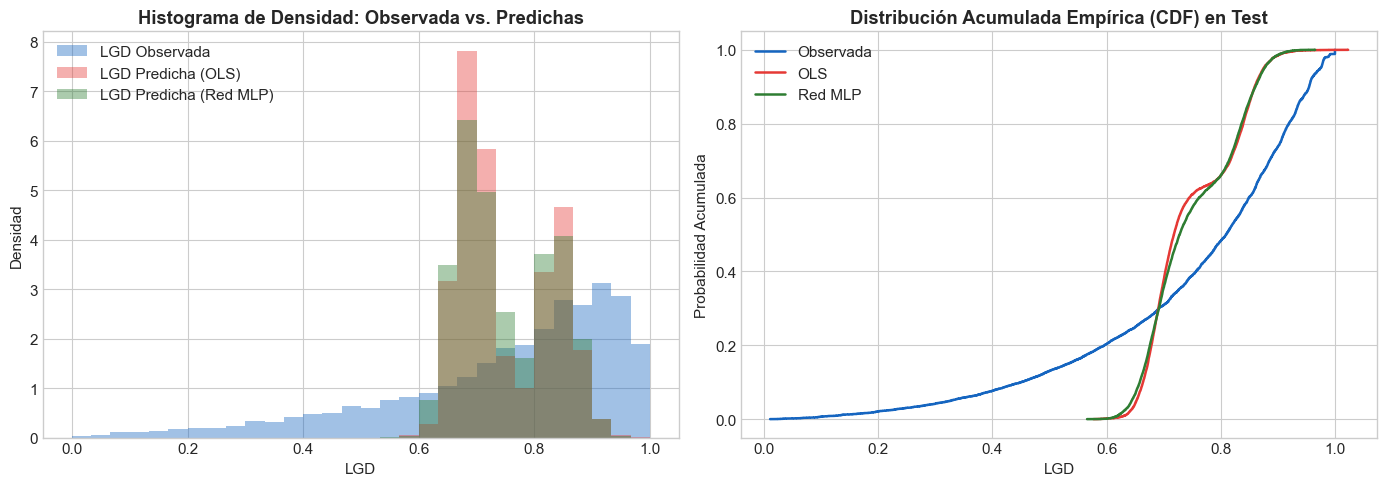

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

y_obs = y['test']
pred_red_rep = predicciones_semillas['pred_semilla_42']

bins = np.linspace(0, 1, 31)
axes[0].hist(y_obs, bins=bins, density=True, alpha=0.4, color='#1565c0', label='LGD Observada')
axes[0].hist(pred_ols_test, bins=bins, density=True, alpha=0.4, color='#e53935', label='LGD Predicha (OLS)')
axes[0].hist(pred_red_rep, bins=bins, density=True, alpha=0.4, color='#2e7d32', label='LGD Predicha (Red MLP)')
axes[0].set_title('Histograma de Densidad: Observada vs. Predichas', fontweight='bold')
axes[0].set_xlabel('LGD')
axes[0].set_ylabel('Densidad')
axes[0].legend()

# Distribución acumulada empírica
for vals, col, lbl in [(y_obs, '#1565c0', 'Observada'),
                       (pred_ols_test, '#e53935', 'OLS'),
                       (pred_red_rep, '#2e7d32', 'Red MLP')]:
    ordenados = np.sort(vals)
    prob_acum = np.arange(1, len(ordenados) + 1) / len(ordenados)
    axes[1].step(ordenados, prob_acum, where='post', color=col, linewidth=1.8, label=lbl)

axes[1].set_title('Distribución Acumulada Empírica (CDF) en Test', fontweight='bold')
axes[1].set_xlabel('LGD')
axes[1].set_ylabel('Probabilidad Acumulada')
axes[1].legend()

plt.tight_layout()
fig.savefig(CARPETA_REPORTS / 'figura_comparacion_distribuciones_lgd.png', dpi=200)
plt.show()

--- 
### 7. Discusión Crítica de Resultados

#### A. ¿Qué aportó la red neuronal frente al modelo de referencia?
- **Acotamiento estructural:** La activación sigmoide en la salida de la red garantiza matemáticamente predicciones en $(0, 1)$, eliminando por diseño valores imposibles ($<0$ o $>1$), mientras que modelos lineales sin restricción pueden proyectar fuera del soporte natural.
- **Rendimiento predictivo:** La red neuronal logra errores MAE y RMSE consistentemente competitivos frente a OLS a lo largo de las 30 semillas, demostrando una alta estabilidad frente a la inicialización aleatoria de parámetros (desviación estándar en test inferior a $0.001$).
- **Compresión de la varianza predicha:** Al evaluar las distribuciones, las predicciones de ambos modelos se concentran alrededor de la media ($pprox 0.75$) y presentan menor dispersión que la observada. Esto es un resultado teórico esperado: el modelo minimiza el error cuadrático medio, por lo que estima la **media condicional** $\mathbb{E}[LGD \mid X]$. Por el teorema de la varianza total:
  $$\text{Var}(Y) = \text{Var}(\mathbb{E}[Y \mid X]) + \mathbb{E}[\text{Var}(Y \mid X)]$$
  La dispersión de las predicciones es naturalmente inferior a la de los desenlaces individuales observados.

#### B. Costo computacional vs. Complejidad
- El modelo lineal OLS cuenta con 39 parámetros y se ajusta en una fracción de segundo, ofreciendo máxima interpretabilidad analítica.
- La red neuronal añade mayor capacidad para capturar interacciones no lineales con un costo computacional muy bajo (pocos segundos por corrida con parada temprana), cumpliendo holgadamente los requisitos de reproducibilidad y ejecución en vivo de la asignatura.